# Практическое задание 2. Диффузионные модели


## Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи).

Сдавать задание после указанного жёсткого срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи !!ВАЖНО!!!
Задания сдаются через систему google classroom. Посылка должна содержать:
* Ноутбук ddpm_hw_bmmo-Username.ipynb

Username &ndash; ваша фамилия и имя на латинице именно в таком порядке

<p style="color:#de3815;font-size:25px;">
Напоминание об оформлении и выполнении ноутбука
</p>

* Все строчки должны быть выполнены. Нужно, чтобы output команды можно было увидеть, не запуская ячейки (кроме редких случаев, когда необходимо намеренно скрыть ненужный output, про такие случаи желательно писать пояснения в тексте). **В противном случае -1 балл**
* При оформлении ДЗ нужно пользоваться данным файлом в качестве шаблона. Не нужно удалять и видоизменять написанный код и текст, если явно не указана такая возможность. **В противном случае -1 балл**
* В anytask обязательно нужно прикреплять отдельно файл с расширением ipynb (не в архиве, а именно отдельно). Если необходимо отправить еще какие-то файлы, то вынесите их в отдельный архив (если файлов много) и пришлите. **В противном случае -0.5 балла*

# В этом задании необходимо будет дореализовать ключевые формулы для обучения дискретной диффузионной модели из статьи DDPM.

[Статья DDPM](https://arxiv.org/pdf/2006.11239.pdf)


---
Для выполнения домашнего задания достаточно использовать Google Colab.

## Об эксперименте

В работе реализованы прямой процесс DDPM, обратный шаг, сэмплер и функция потерь. Модель обучается предсказывать шум, добавленный к изображению. После обучения я оцениваю генерации по сетке изображений и по FID.

| Параметр | Значение |
| --- | --- |
| Данные | MNIST, обучающая выборка |
| Размер изображения | 1 × 32 × 32, значения от −1 до 1 |
| Модель | U-Net, базовая размерность 64, множители (1, 2, 4, 4) |
| Прямой процесс | 1000 шагов; линейное расписание β от 0,0001 до 0,02 |
| Обучение | 5000 итераций, батч 128 |
| Оптимизатор | AdamW, learning rate 0,0002, weight decay 0,01 |
| Функция потерь | MSE между добавленным и предсказанным шумом |
| EMA | Коэффициент 0,999; для генерации используются EMA-веса |
| Seed | 42 |
| Оценка качества | 5000 реальных и 5000 сгенерированных изображений |

**Повторный запуск.** В Colab нужно выбрать GPU и выполнить все ячейки сверху вниз. W&B попросит войти в аккаунт; ключ вводится в скрытом поле, сохранять его в коде не нужно. В файле оставлены результаты выполненного запуска. После нового запуска таблицы, графики и численные итоги обновятся. На другом GPU возможны небольшие отличия.

В готовых частях шаблона исправлены проверки `assert`, загрузка Inception и сохранение PNG. Также добавлены история loss, прогрев перед замерами времени и повторная генерация в ту же папку. Формулы DDPM и обработка изображений для FID соответствуют заданию.


In [1]:
!python3 -V
import torch


print(f'torch.__version__: {torch.__version__}')

Python 3.13.15
torch.__version__: 2.11.0+cu130


In [2]:
!pip3 install wandb comet_ml==3.55.0 -q     #установка логгеров
!pip3 install torch_ema==0.3 denoising_diffusion_pytorch==2.2.5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.9/780.9 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 65.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.7/83.7 kB 4.0 MB/s eta 0:00:00


В задании по умолчанию выбран логгер wandb, вы можете, также использовать логгер comet_ml. В Anytask помимо ноутбука **надо будет сдать ссылку на публичный проект** в одном из этих логгеров.

In [3]:
import torch
import numpy as np
import random


def set_global_seed(seed: int) -> None:
    """
    Set global seed for reproducibility.
    """

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    random.seed(seed)
    np.random.seed(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_global_seed(42)

In [4]:
import platform
from IPython.display import display, Markdown

torch.set_num_threads(min(torch.get_num_threads(), 4))
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("CUDA доступна:", torch.cuda.is_available())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
else:
    raise RuntimeError("Для полного запуска выберите GPU в настройках среды Colab.")


Python: 3.13.15
PyTorch: 2.11.0+cu130
Устройство: cuda:0
CUDA доступна: True
GPU: NVIDIA A100-SXM4-40GB


# Датасет

In [5]:
import os
import numpy as np
import PIL

from tqdm import tqdm
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, Dataset
from typing import Generator, Tuple, Dict, Optional, Union
from torch import Tensor
from cv2 import resize


def preprocess_image(image: "PIL.Image") -> np.ndarray:
    image = np.array(image, dtype=np.uint8)
    image = resize(image, (32, 32))
    return np.array(image, dtype=np.float32) / 127.5 - 1


def postprocess_image(image: torch.Tensor) -> torch.Tensor:
    # convert values to [0; 255]
    image = image.cpu().detach()
    image = (image + 1) * 127.5
    image = torch.clip(image, 0, 255)
    return image


class MnistDataset(Dataset):
    def __init__(self, train: bool = True):
        super().__init__()
        self.mnist = MNIST(
            'data',
            train=train,
            download=True
        )

    def __len__(self) -> int:
        return len(self.mnist)

    def __getitem__(self, index: int) -> Dict[str, Tensor]:
        image, target = self.mnist[index]
        image = preprocess_image(image)
        target = int(target)
        return {
            "images": Tensor(image)[None],
            "targets": target
        }

In [6]:
def dict_to_device(dct: Dict[str, Tensor], device: torch.device) -> Dict[str, Tensor]:
    return {k: v.to(device) for k, v in dct.items()}


def get_train_images_generator(
    batch_size: int = 128,
    num_workers: int = 0,
    shuffle: bool = True,
    drop_last: bool = True
) -> Generator[Dict[str, Tensor], None, None]:
    dataset = MnistDataset(train=True)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        num_workers=num_workers,
        shuffle=shuffle,
        drop_last=drop_last
    )
    while True:
        yield from loader

In [7]:
def check_generator(batch_size: int = 128):
    generator = get_train_images_generator(batch_size)
    batch_dict = next(generator)
    assert batch_dict['images'].shape == (batch_size, 1, 32, 32), batch_dict['images'].shape
    assert batch_dict['targets'].shape == (batch_size,), batch_dict['targets'].shape

check_generator(131)


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.17MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.06MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.1MB/s]


# DDPM's dynamic (5 баллов)



В `get_coeffs_primities` (2 pts) необходимо в возвращаеый словарь добавить рассчет коэффицентов, при помощи которых вы сможете реализовать семплирование из распределений $q(x_t | x_0), q(x_t | x_{t+1}, x_0), p(x_t | x_{t + 1})$.

Например:
- $\alpha_t = 1 - \beta_t$
- $\bar{\alpha_t} = \prod_{t=1}^{T} \alpha_t$
- $\sqrt{\bar{\alpha_t}}$
- ...
- любые коэффиценты, которые помогут вам рассчитать коэффиценты в $q(x_t | x_0), q(x_t | x_{t+1}, x_0), p(x_t | x_{t + 1})$

`extract_values_from_times` - по батчу с целочислненными временами выдает батч коэфиицентов в нужном шейпе для перемножения с батчом картинок


В коде время нумеруется от 0 до $T-1$, поэтому индекс 0 соответствует первому шагу из лекции.

$$
q(x_t\mid x_0)=\mathcal N\left(
\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right).
$$

Для обратного условного распределения использую
$$
\tilde\beta_t=
\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t},\qquad
\tilde\mu_t=
\frac{\beta_t\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_t}x_0+
\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t.
$$

Перед первым шагом $\bar\alpha=1$. При индексе 0 дисперсия posterior равна нулю, а среднее равно $x_0$. В сэмплере подставляю оценку $x_0$, восстановленную по предсказанному шуму.

In [8]:
from torch import nn


def get_coeffs_primitives(
    T: int = 1000,
    beta_min: float = 1e-4,
    beta_max: float = 2e-2,
) -> Dict[str, Tensor]:
    """
    output: Dict[str, Tensor]
      {
        "a": b
      }
    ---
    b.shape == (T,)
    """
    betas = torch.linspace(beta_min, beta_max, T).float()
    alphas = 1 - betas

    sqrt_alphas = torch.sqrt(alphas)
    alphas_hat = torch.cumprod(1 - betas.double(), dim=0)

    alphas_hat_prev = torch.cat([alphas_hat.new_ones(1), alphas_hat[:-1]])

    sqrt_alphas_hat = torch.sqrt(alphas_hat)
    sqrt_1m_alphas_hat = torch.sqrt(1 - alphas_hat)
    posterior_variance = betas * (1 - alphas_hat_prev) / (1 - alphas_hat)
    posterior_mean_coef_0 = betas * torch.sqrt(alphas_hat_prev) / (1 - alphas_hat)
    posterior_mean_coef_t = sqrt_alphas * (1 - alphas_hat_prev) / (1 - alphas_hat)

    posterior_mean_coef_0[0] = 1
    posterior_mean_coef_t[0] = 0
    posterior_variance[0] = 0

    return {
        "betas": betas,
        "alphas": alphas,
        "sqrt_alphas": sqrt_alphas,
        "alphas_hat": alphas_hat.float(),
        "alphas_hat_prev": alphas_hat_prev.float(),
        "sqrt_alphas_hat": sqrt_alphas_hat.float(),
        "sqrt_1m_alphas_hat": sqrt_1m_alphas_hat.float(),
        "posterior_mean_coef_0": posterior_mean_coef_0.float(),
        "posterior_mean_coef_t": posterior_mean_coef_t.float(),
        "posterior_variance": posterior_variance.float(),
        "sqrt_posterior_variance": torch.sqrt(posterior_variance.clamp_min(0)).float(),
    }



def extract_values_from_times(values: Tensor, times: torch.LongTensor) -> Tensor:
    values = values[times]
    return values[:, None, None, None]


## Релизуйте DDPMDynamic (3 балла)

`DDPMDynamic`:
- `__init__` - получаем коэффиценты, добавляем их в класс, как атрибуты, чтобы доставать их по имени без использования словаря
- `sample_from_posterior_q(x_t: FloatTensor, x_0: FloatTensor, t: LongTensor)` - $ x_{t-1} \sim q(x_{t-1} | x_{t}, x_0) $
- `forward` - $ x_{t} \sim q(x_t | x_0) $

In [9]:
class DDPMDynamic(nn.Module):
    def __init__(
        self,
        T: int = 1000,
        beta_min: float = 1e-4,
        beta_max: float = 2e-2,
    ):
        super().__init__()
        self.T = T

        coeffs_primitives = get_coeffs_primitives(T, beta_min, beta_max)

        for name, tensor in coeffs_primitives.items():
            self.register_buffer(name, tensor)

    def sample_time_on_device(self, batch_size: int = 1, device: torch.device = torch.device('cpu')):
        return torch.randint(0, self.T, (batch_size,), device=device)

    def sample_from_posterior_q(
        self,
        x_t: Tensor,
        x_0: Tensor,
        t: torch.LongTensor
    ) -> Tensor:

        coef_0 = extract_values_from_times(self.posterior_mean_coef_0, t)
        coef_t = extract_values_from_times(self.posterior_mean_coef_t, t)
        std = extract_values_from_times(self.sqrt_posterior_variance, t)
        mean = coef_0 * x_0 + coef_t * x_t
        return mean + std * torch.randn_like(x_t)

    def get_x_zero(
        self,
        x_t: Tensor,
        eps: Tensor,
        t: torch.LongTensor
    ) -> Tensor:
        sqrt_alphas_hat = extract_values_from_times(self.sqrt_alphas_hat, t)
        sqrt_1m_alphas_hat = extract_values_from_times(self.sqrt_1m_alphas_hat, t)

        x_0 = (x_t - sqrt_1m_alphas_hat * eps) / sqrt_alphas_hat
        return x_0

    def forward(self, batch: Dict[str, Tensor]) -> Dict[str, Tensor]:
        r"""
            Dict:
                x_0 - clean_image
                t - time (int \in [0; T - 1])
                eps - Optional[corresponding noise]
        Returns:
            Dict:
                x_t - noised_sample
                eps - corresponding noise
        """
        x_0 = batch['x_0']
        t = batch['time']

        eps = batch.get("eps")
        if eps is None:
            eps = torch.randn_like(x_0)

        signal_scale = extract_values_from_times(self.sqrt_alphas_hat, t)
        noise_scale = extract_values_from_times(self.sqrt_1m_alphas_hat, t)
        x_t = signal_scale * x_0 + noise_scale * eps

        return {
            "x_t": x_t,
            "eps": eps
        }


In [10]:
def check_ddpm_dynamic():
    dynamic = DDPMDynamic()
    device = torch.device('cuda:0')
    dynamic.to(device)
    times = dynamic.sample_time_on_device(10, device)
    assert times.device == device, f'{times.device}, {device}'
    assert times.shape == (10,)

check_ddpm_dynamic()

## Реализуйте генерация (1.5 балла)

`Sampler`/DDPM's cycle:
- `single_step` - необходимо просемплировать $x_{t-1} \sim p(x_{t-1}|x_t)$
- `sample` - весь процесс обхода по марковской цепочки семплирования

In [11]:
from tqdm.auto import trange


class Sampler(nn.Module):
    def __init__(
        self,
        ddpm: nn.Module,
        dynamic: DDPMDynamic
    ):
        super().__init__()
        ddpm.eval()
        self.ddpm = ddpm
        self.dynamic = dynamic

    @torch.no_grad()
    def single_step(self, x_t, t):

        eps = self.ddpm(x_t, t)
        x_0 = self.dynamic.get_x_zero(x_t, eps, t)
        return self.dynamic.sample_from_posterior_q(x_t, x_0, t)

    @torch.no_grad()
    def sample(
        self,
        shape: Tuple[int, int, int, int],
        device: torch.device = torch.device('cpu'),
        verbose: bool = False
    ) -> Tensor:
        self.ddpm.eval()
        x_t = torch.randn(shape, device=device)
        batch_size = shape[0]

        bar = trange if verbose else range
        for t in bar(self.dynamic.T - 1, -1, -1):
            t_tensor = torch.ones(batch_size, dtype=torch.int64, device=device) * t
            x_t = self.single_step(x_t, t_tensor)
        return x_t


### Проверка динамики и обратного шага

In [12]:
def check_formulas():
    set_global_seed(42)
    dynamic = DDPMDynamic()
    assert torch.all(dynamic.betas > 0)
    assert torch.all(dynamic.alphas_hat[1:] < dynamic.alphas_hat[:-1])
    assert torch.all(dynamic.posterior_variance >= 0)
    assert dynamic.posterior_variance[0] == 0

    clean = torch.randn(3, 1, 8, 8)
    noise = torch.randn_like(clean)
    times = torch.tensor([0, 17, 999])
    batch = dynamic({"x_0": clean, "time": times, "eps": noise})
    expected = (
        dynamic.sqrt_alphas_hat[times, None, None, None] * clean
        + dynamic.sqrt_1m_alphas_hat[times, None, None, None] * noise
    )
    assert torch.allclose(batch["x_t"], expected)
    assert torch.equal(batch["eps"], noise)
    restored = dynamic.get_x_zero(batch["x_t"], noise, times)
    assert torch.allclose(restored, clean, atol=3e-5)

    first = torch.zeros(3, dtype=torch.long)
    posterior_first = dynamic.sample_from_posterior_q(torch.randn_like(clean), clean, first)
    assert torch.equal(posterior_first, clean)
    assert dynamic({"x_0": clean, "time": times})["x_t"].shape == clean.shape

    class ZeroDenoiser(nn.Module):
        def __init__(self):
            super().__init__()
            self.times = []

        def forward(self, images, time):
            self.times.append(int(time[0]))
            return torch.zeros_like(images)

    denoiser = ZeroDenoiser()
    sampler = Sampler(denoiser, dynamic)
    noisy = torch.randn(3, 1, 8, 8)
    times = torch.tensor([0, 8, 999])
    set_global_seed(11)
    actual = sampler.single_step(noisy, times)
    set_global_seed(11)
    expected_mean = noisy / dynamic.sqrt_alphas[times, None, None, None]
    expected = expected_mean + (
        dynamic.sqrt_posterior_variance[times, None, None, None]
        * torch.randn_like(noisy)
    )
    assert torch.allclose(actual, expected, atol=1e-5, rtol=1e-5)

    short_model = ZeroDenoiser()
    images = Sampler(short_model, DDPMDynamic(T=5)).sample((2, 1, 8, 8))
    assert images.shape == (2, 1, 8, 8)
    assert torch.isfinite(images).all()
    assert short_model.times == [4, 3, 2, 1, 0]
    print("Коэффициенты, прямой процесс, posterior и цикл сэмплирования: OK")

check_formulas()

Коэффициенты, прямой процесс, posterior и цикл сэмплирования: OK


## Обучение (1.5 балла)

При помощи примитивов сверху реализовать обучение DDPM. Алгоритм обучения представлен ниже.

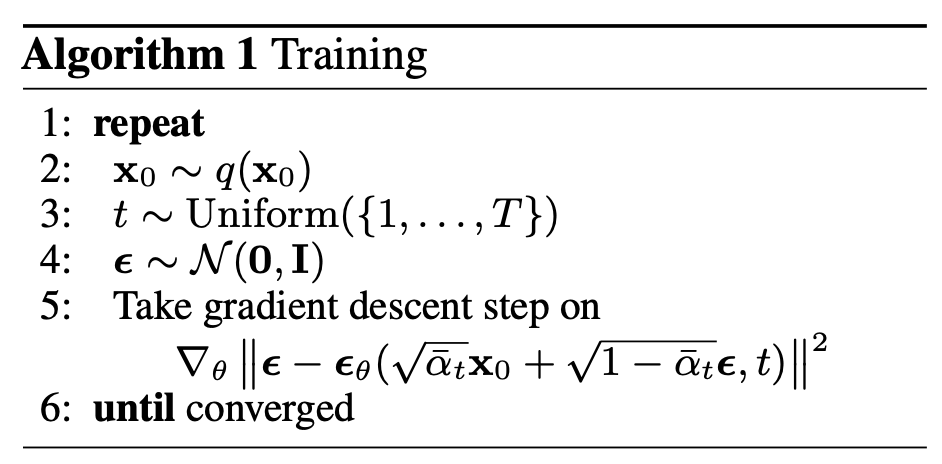


`DiffusionTrainer`:
- `calc_loss(clean_images: FloatTensor)` - необходимо внутри метода просемплировать время, далее просемплировать $x_t$, обработать батч, рассчитать лосс для обучения

In [13]:
import wandb
import comet_ml
from getpass import getpass

USE_COMET = False
training_history = []
experiment_url = None
project_url = None


def logger_start(project_name, run_name, use_comet=USE_COMET):
    global experiment_url, project_url, training_history
    training_history = []
    if use_comet:
        api_key = os.environ.get("COMET_API_KEY") or getpass("Comet API key: ")
        experiment = comet_ml.start(
            api_key=api_key,
            project_name=project_name,
            online=True
        )
        experiment.set_name(run_name)
        experiment_url = experiment.url
        project_url = None
    else:
        wandb.login()
        run = wandb.init(
            project=project_name,
            name=run_name,
            mode="online",
            config={
                "dataset": "MNIST", "image_size": 32, "seed": 42,
                "diffusion_steps": 1000, "train_steps": 5000,
                "batch_size": 128, "lr": 2e-4,
                "weight_decay": 1e-2, "ema_decay": 0.999
            }
        )
        experiment_url = run.url
        project_url = run.url.split("/runs/")[0]
    print(f"Эксперимент: {experiment_url}")


def log_metrics(d, step, use_comet=USE_COMET):
    values = {
        name: float(value.detach().cpu()) if isinstance(value, torch.Tensor) else value
        for name, value in d.items()
    }
    if "mse/train" in values:
        training_history.append({"step": step, "mse": values["mse/train"]})
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.log_metrics(values, step=step)
    else:
        wandb.log(values, step=step)


def log_images(img, img_name, step, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.log_image(image_data=img, name=img_name, step=step)
    else:
        wandb.log({img_name: wandb.Image(img)}, step=step)


def logger_end(use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.end()
    else:
        wandb.finish()


In [14]:
from torch_ema import ExponentialMovingAverage
import math
import torchvision


class DiffusionTrainer:
    def __init__(
        self,
        ddpm: nn.Module,
        dynamic: DDPMDynamic,
        device: torch.device = torch.device('cpu')
    ):
        self.ddpm = ddpm
        self.dynamic = dynamic

        self.dynamic.to(device)
        self.ddpm.to(device)

        self.sampler = Sampler(ddpm, dynamic)
        self.sampler.to(device)

        self.ema = ExponentialMovingAverage(ddpm.parameters(), decay=0.999)

        self.device = device


        self.optimizer = torch.optim.AdamW(
            self.ddpm.parameters(),
            lr=2e-4,
            weight_decay=1e-2
        )

        self.step = 0

    def switch_to_ema(self) -> None:
        self.ema.store(self.ddpm.parameters())
        self.ema.copy_to(self.ddpm.parameters())

    def switch_back_from_ema(self) -> None:
        self.ema.restore(self.ddpm.parameters())

    def calc_loss(self, x_0: torch.Tensor) -> torch.Tensor:

        times = self.dynamic.sample_time_on_device(x_0.shape[0], x_0.device)
        batch = self.dynamic({"x_0": x_0, "time": times})
        eps_pred = self.ddpm(batch["x_t"], times)
        return nn.functional.mse_loss(eps_pred, batch["eps"])

    def log_metric(self, metric_name: str, loader_name: str, value: Union[float, torch.Tensor]):
        log_metrics({f'{metric_name}/{loader_name}': value}, step=self.step)

    def log_image(self, metric_name: str, loader_name: str, value: torch.Tensor):
        log_images(value, f'{metric_name}/{loader_name}', step=self.step)

    def optimizer_logic(self, loss: torch.Tensor) -> None:
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.ema.update(self.ddpm.parameters())

    def train(
            self,
            train_generator: Generator[Dict[str, Tensor], None, None],
            total_iters: int = 1000,
            project_name: str = 'discrete_time_ddpm',
            experiment_name: str = 'mnist_baseline'
        ) -> None:
        logger_start(project_name=project_name, run_name=experiment_name)
        self.ddpm.train()

        for iter_idx in trange(1, 1 + total_iters):
            self.step = iter_idx

            batch = next(train_generator)
            batch = dict_to_device(batch, device=self.device)

            loss = self.calc_loss(x_0=batch['images'])
            self.log_metric('mse', 'train', loss)

            self.optimizer_logic(loss)

            if iter_idx % 1000 == 0:
                self.snapshot()

        self.ddpm.eval()
        self.switch_to_ema()

        logger_end()

    @torch.no_grad()
    def sample_images(
            self, batch_size: int,
            verbose: bool = False
    ) -> torch.Tensor:
        x_pred = self.sampler.sample((batch_size, 1, 32, 32), self.device, verbose)
        x_pred = postprocess_image(x_pred)
        return x_pred

    @torch.no_grad()
    def snapshot(self) -> None:
        prev_mode = self.ddpm.training

        self.ddpm.eval()
        self.switch_to_ema()

        images = self.sample_images(100).cpu()
        nrow = 10
        grid = torchvision.utils.make_grid(images, nrow=nrow).permute(1, 2, 0)
        grid = grid.data.numpy().astype(np.uint8)
        self.log_image('images', 'from_noise', grid)

        self.switch_back_from_ema()
        self.ddpm.train(prev_mode)


### Проверка функции потерь

In [15]:
def check_loss_and_gradients():
    set_global_seed(42)

    class SmallDenoiser(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv = nn.Conv2d(1, 1, kernel_size=1)

        def forward(self, images, times):
            return self.conv(images)

    model = SmallDenoiser()
    trainer_check = DiffusionTrainer(model, DDPMDynamic(T=10))
    clean = torch.randn(4, 1, 8, 8)
    loss = trainer_check.calc_loss(clean)
    assert loss.ndim == 0 and torch.isfinite(loss)
    weights_before = model.conv.weight.detach().clone()
    trainer_check.optimizer_logic(loss)
    assert model.conv.weight.grad is not None
    assert torch.isfinite(model.conv.weight.grad).all()
    assert not torch.equal(model.conv.weight, weights_before)
    print(f"Loss и шаг оптимизатора: OK; тестовый MSE = {loss.item():.6f}")

check_loss_and_gradients()

Loss и шаг оптимизатора: OK; тестовый MSE = 2.141253


In [16]:
from denoising_diffusion_pytorch import Unet

set_global_seed(42)

ddpm = Unet(
    dim=64,
    dim_mults=(1, 2, 4, 4),
    channels=1,
    flash_attn=True
)

Non-A100 GPU detected, using math or mem efficient attention if input tensor is on cuda


In [17]:
set_global_seed(42)
images_check = torch.randn(2, 1, 32, 32)
times_check = torch.tensor([0, 999])
with torch.no_grad():
    output_check = ddpm(images_check, times_check)
assert output_check.shape == images_check.shape
assert torch.isfinite(output_check).all()
print("Прямой проход U-Net на двух изображениях: OK")

Прямой проход U-Net на двух изображениях: OK


In [18]:
device = torch.device('cuda:0')

In [19]:
trainer = DiffusionTrainer(
    ddpm,
    DDPMDynamic(),
    device
)

In [20]:
generator = get_train_images_generator(128)

Если у вас будут проблемы с wandb, то можете перейти в comet_ml. **Не оставляйте свой API ключ в сданном ноутбуке!**

In [21]:
# Время обучения около 45 минут

trainer.train(
    generator,
    total_iters=5000
)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: wandb_v1_UzN6Pa3IG5yVshRTzfn21WRnVDN


wandb: WARNING Invalid choice


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


...

wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: aashutov05 (aashutov05-higher-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Эксперимент: https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm/runs/rtu1kq01


  0%|          | 0/5000 [00:00<?, ?it/s]

mse/train,█▅▄▃▃▂▂▂▃▁▁▂▁▁▁▁▂▂▁▂▁▁▁▁▂▁▂▂▁▁▂▂▂▁▁▁▁▁▁▂
mse/train,0.02343


### Результаты обучения

Ниже показана средняя MSE за последние 100 итераций. Такое сглаживание помогает увидеть общую динамику: отдельные батчи дают шумные значения loss. Для сравнения также вывожу последний MSE и средний MSE за последние 100 шагов.

,Показатель,Значение
0,Итераций,5000
1,Последний MSE,0.02343
2,Средний MSE за последние 100 итераций,0.01676


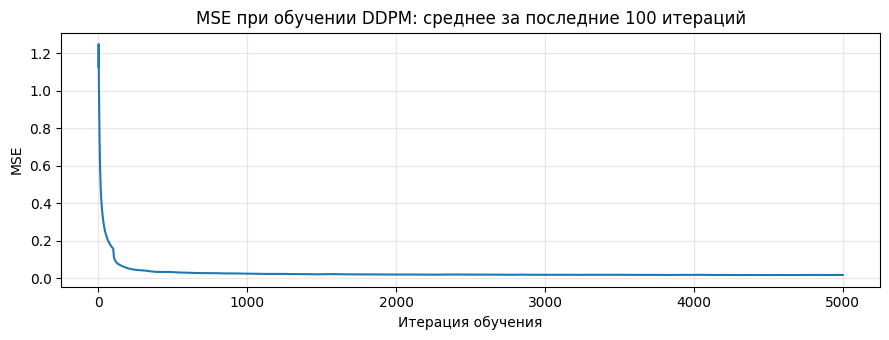

In [22]:
import pandas as pd
from matplotlib import pyplot as plt

loss_history = pd.DataFrame(training_history)
assert len(loss_history) == trainer.step == 5000
assert np.isfinite(loss_history["mse"]).all()
last_train_mse = float(loss_history["mse"].iloc[-1])
mean_last_100 = float(loss_history["mse"].tail(100).mean())

display(pd.DataFrame({
    "Показатель": ["Итераций", "Последний MSE", "Средний MSE за последние 100 итераций"],
    "Значение": [str(len(loss_history)), f"{last_train_mse:.5f}", f"{mean_last_100:.5f}"]
}))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(loss_history["step"], loss_history["mse"].rolling(100, min_periods=1).mean())
ax.set_xlabel("Итерация обучения")
ax.set_ylabel("MSE")
ax.set_title("MSE при обучении DDPM: среднее за последние 100 итераций")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Вы обучили большую модель, самое важное ее сохранить и не потерять!!! Мы будем использовать ema сглаженные веса, так как на них обычно достигается лучше качество генерации. Подробнее про сглаживание можно почитать в статье [Averaging Weights Leads to Wider Optima and Better Generalization](https://arxiv.org/abs/1803.05407).

In [23]:
trainer.switch_to_ema()
torch.save(ddpm.state_dict(), "./pretrained_ddpm_checkpoint.pth")

Если вы используете облачные сервисы, то лучше сохранить на устройство локально, так как при перезапуске сессий очень часто пропадают файлы!

# Безусловная генерация неплохих изображений  (1 балл)

  0%|          | 0/1000 [00:00<?, ?it/s]

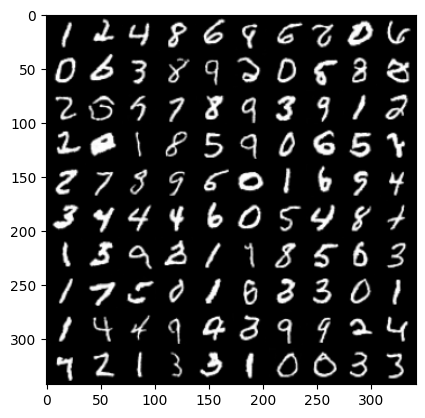

In [24]:
from matplotlib import pyplot as plt
import math

@torch.inference_mode()
def sample_images(
    sampler: Sampler, batch_size: int = 100,
    device = torch.device('cpu'),
    verbose: bool = True
):
    images = sampler.sample((batch_size, 1, 32, 32), device, True)
    images = postprocess_image(images)
    images = images.cpu()
    nrow = int(math.ceil(math.sqrt(batch_size)))
    grid = torchvision.utils.make_grid(images, nrow=nrow).permute(1, 2, 0)
    grid = grid.data.numpy().astype(np.uint8)
    return grid

grid = sample_images(trainer.sampler, 100, trainer.device)

plt.imshow(grid)
plt.show()

# Опишите ваши выводы/результаты: (1 балл)

- За 5000 итераций модель научилась восстанавливать рукописные цифры из шума. В истории обучения MSE в целом снижается, хотя отдельные значения колеблются: на каждом шаге меняются изображения, время зашумления и сам шум.
- На сетке из 100 изображений большинство цифр читаются. Есть разные цифры и разные начертания, явного сведения всех генераций к одному символу не видно.
- Качество не одинаково для всех изображений. Некоторые символы деформированы или похожи сразу на несколько цифр. Поэтому по этой сетке нельзя утверждать, что все генерации корректны.
- Для генерации использованы EMA-веса. Проверки отдельно подтверждают, что обратный процесс проходит все 1000 шагов, а на последнем шаге дополнительный шум не добавляется.

Численные результаты обучения приведены над этой сеткой. Последний MSE относится к одному обучающему батчу; это не точность распознавания и не оценка на тестовой выборке. Сетка показывает качество отдельных изображений, а FID ниже позволяет сравнить распределения признаков реальных и сгенерированных изображений.


# Оценка качества (3 балла)

Выше мы обучили модель и визуально оценили качество сэмплов, теперь возникает вопрос: как получить объективную метрику качества модели. Один из вариантов получения объективной оценки &ndash; ответить на вопрос: насколько распределение генерируемых моделью изображений "похоже" на распределение истинных изображений.

Таким образом, мы свели задачу объективной оценки к нахождению схожести между распределениями.

Существует множество способов оценки схожести распределений. В области computer vision популярным способом является **FID (Fréchet Inception Distance)**. Данная метрика вычисляет квадрат \textit{расстояния Вассерштейна-$2$} между распределениями активаций некоторой обученной свёрточной модели.

Подробнее смотрите в статье [GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium](https://arxiv.org/abs/1706.08500).

Более конкретно, положим, что есть два множества изображений, которые мы хотим сравнить:
\begin{equation}
    A = \{a_{i}\}, B = \{b_{j}\}, \quad a_{i}, b_{i} \in \mathcal{I}.
\end{equation}

Рассмотрим глубокую свёрточную модель для извлечения векторных представлений:
\begin{equation}
    M: \mathcal{I} \rightarrow \mathbb{R}^{d}.    
\end{equation}

Предположим, что
\begin{align}
    &M(a) \sim \mathcal{N}(\mu_{A}, \Sigma_{A}),\\
    &M(b) \sim \mathcal{N}(\mu_{B}, \Sigma_{B}).
\end{align}

Предположение метрики FID утверждает, что если распределения $M(a)$, $M(b)$ близки друг к другу, то и множества изображений $A$, $B$ похожи. Данное утверждение было проверено эмпирически.

В качестве меры близости между распределениями используется *расстояние Вассерштейна-$2$*:
\begin{equation}
    \textbf{FID} = \mathcal{W}^2_{2}(\mathcal{N}(\mu_{A}, \Sigma_{A}), \mathcal{N}(\mu_{B}, \Sigma_{B})) = ||\mu_{A} - \mu_{B}||_{2}^{2} + \text{Tr}\Big( \Sigma_{A} + \Sigma_{B} - 2 \sqrt{\Sigma_{A} \Sigma_{B}} \Big). \tag{1}
\end{equation}

Стандартным выбором для модели выделения признаков $M$ является **Inception V3**. В частности, берутся активации после Average Pooling, что даёт размерность признакового вектора $d = 2048$.

Для подсчёта метрик обычно фиксируют некоторое количество сгенерированных изображений. Типичный размер $|A| = 5000$ или $50000$.

В этом задании вам предлагается получить график зависимости FID от размера выборки. Генерировать $50000$ изображений займет много времени, поэтому вам необходимо будет один раз сгенерировать $5000$ изображений и взять $K = [200, 500, 1000, 2000, 3000, 4000, 5000]$ изображений при подсчете метрики.

Для удобства вы можете брать первые $K$ изображений.

Загрузим модель для подсчёта активаций. Уберём последний линейный слой и дропаут для получения активаций после Average Pool:

In [25]:
from torchvision import transforms

In [26]:
inception_model = torchvision.models.inception_v3(
    weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1
)
inception_model.dropout = torch.nn.Identity()
inception_model.fc = torch.nn.Identity()
inception_model.eval()

inception_transform = transforms.Compose([
    transforms.Resize(299),
    transforms.CenterCrop(299),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 173MB/s]


Реализуйте датасет обёртку для обработки папки с изображениями:

In [27]:
import glob # glob.glob(template) помогает искать файлы по template

class ImagesDataset(Dataset):
    def __init__(self, template: str, transform):
        """
        :param str template: Path to the images
        :param Callable[PIL.Image.Image, torch.Tensor] transform: Image transform
        """
        super().__init__()

        self.paths = sorted(glob.glob(template))

        self.transform = transform
        if not self.paths:
            raise ValueError(f"Изображения не найдены: {template}")

    def __len__(self) -> int:
        """
        Number of images
        :rtype: int
        """
        return len(self.paths)

    def __getitem__(self, idx: int) -> torch.Tensor:
        """
        :param int idx: Image Id
        :return:
        :rtype: torch.Tensor
        """
        # Inception ожидает RGB изображения
        image = PIL.Image.open(self.paths[idx]).convert("RGB")
        return self.transform(image)


Теперь реализуем функцию для подсчёта активаций для всех изображений в заданной директории:

In [28]:
@torch.inference_mode()
def get_activations(
    template: str, model: torch.nn.Module, transform, batch_size: int, device: torch.device
) -> np.ndarray:
    """Compute activations for all images specified by template
    :param str template: Path to the images
    :param torch.nn.Module model: Model that compute activations
    :param Callable[PIL.Image.Image, torch.Tensor] transform: Image transform
    :param int batch_size: Batch size to perform a forward pass
    :param torch.device device: Target device
    :return: 2D array of activations
    :rtype: np.ndarray
    """
    model.to(device)
    model.eval()

    dataset = ImagesDataset(template, transform=transform)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    features = []
    for images in tqdm(
        dataloader, total=len(dataloader), desc=f'Compute activations for the {template}'
    ):
        images = images.to(device)
        output = model(images).cpu()
        features.append(output)

    return torch.cat(features, dim=0).numpy()


Выгрузим MNIST в формате `.png`.

In [29]:
def extract_dataset(folder: str, count: int = 5000):

    os.makedirs(folder, exist_ok=True)
    data = MnistDataset()

    for i in tqdm(range(count)):
        img = data[i]['images']
        img = postprocess_image(img)
        img = img.cpu().permute(1, 2, 0).numpy().astype('uint8')

        file_name = os.path.join(folder, f'img_{i:05d}.png')
        PIL.Image.fromarray(img[:, :, 0]).save(file_name)


In [30]:
mnist_images_path = './mnist_images/'
extract_dataset('./mnist_images/')

100%|██████████| 5000/5000 [00:02<00:00, 1926.74it/s]


In [31]:
assert len(glob.glob("./mnist_images/*.png")) == 5000

In [32]:
activation_batch_size = 256 if device.type == "cuda" else 16
activations_real = get_activations(
    mnist_images_path + "*.png",
    inception_model,
    inception_transform,
    batch_size=activation_batch_size,
    device=device
)


Compute activations for the ./mnist_images/*.png: 100%|██████████| 20/20 [00:13<00:00,  1.46it/s]


In [33]:
assert activations_real.shape == (5000, 2048)
assert np.allclose(np.linalg.norm(activations_real), 1380.5614, atol=1.0)

Теперь реализуем подсчёт FID по формуле (1).

In [34]:
import scipy


def compute_fid(activations_real: np.ndarray, activations_fake: np.ndarray) -> float:
    """
    :param np.ndarray activations_real: Activations for the real images
    :param np.ndarray activations_fake: Activations for the fake images
    """
    real = np.asarray(activations_real, dtype=np.float64)
    fake = np.asarray(activations_fake, dtype=np.float64)

    if real.ndim != 2 or fake.ndim != 2 or real.shape[1] != fake.shape[1]:
        raise ValueError("Ожидаются две матрицы с одинаковым числом признаков.")
    if min(len(real), len(fake)) < 2:
        raise ValueError("Для ковариации нужны хотя бы два изображения.")
    if not np.isfinite(real).all() or not np.isfinite(fake).all():
        raise ValueError("Активации содержат NaN или бесконечность.")
    if np.array_equal(real, fake):
        return 0.0

    mean_real = real.mean(axis=0)
    mean_fake = fake.mean(axis=0)
    cov_real = np.atleast_2d(np.cov(real, rowvar=False))
    cov_fake = np.atleast_2d(np.cov(fake, rowvar=False))

    if not np.any(cov_real) or not np.any(cov_fake):
        cross_trace = 0.0
    else:
        cov_sqrt = scipy.linalg.sqrtm(cov_real @ cov_fake)
        if not np.isfinite(cov_sqrt).all():
            offset = np.eye(cov_real.shape[0]) * 1e-6
            cov_sqrt = scipy.linalg.sqrtm((cov_real + offset) @ (cov_fake + offset))
        if np.iscomplexobj(cov_sqrt):
            if np.max(np.abs(np.diag(cov_sqrt).imag)) > 1e-3:
                raise ValueError("У матричного корня большая мнимая часть.")
            cov_sqrt = cov_sqrt.real
        cross_trace = np.trace(cov_sqrt)

    mean_distance = np.sum((mean_real - mean_fake) ** 2)
    fid = mean_distance + np.trace(cov_real) + np.trace(cov_fake) - 2 * cross_trace
    if not np.isfinite(fid):
        raise ValueError("Не удалось получить конечное значение FID.")
    return float(max(fid, 0.0))


In [35]:
def check_fid_formula():
    points = np.array([
        [-1., -1.], [-1., 1.], [1., -1.], [1., 1.]
    ])
    assert compute_fid(points, points) == 0
    assert np.isclose(compute_fid(points, points + [2., -3.]), 13.)
    assert np.isclose(compute_fid(points, np.zeros((3, 2))), 8 / 3)
    assert np.isclose(compute_fid(points, 2 * points), 8 / 3)
    assert np.isclose(
        compute_fid(points, 2 * points),
        compute_fid(2 * points, points)
    )
    print("FID: сдвиг среднего, изменение ковариации, симметрия и вырожденная выборка: OK")

check_fid_formula()

FID: сдвиг среднего, изменение ковариации, симметрия и вырожденная выборка: OK


In [36]:
assert np.allclose(compute_fid(activations_real, activations_real), 0.0)
assert np.allclose(compute_fid(activations_real, np.ones((13, 2048))), 1291.0, atol=1.0)
assert np.allclose(compute_fid(activations_real, np.zeros((13, 2048))), 381.0, atol=1.0)

Теперь перейдем к генерации изображений с помощью диффузионной модели.

In [37]:
set_global_seed(42)
device = torch.device('cuda:0')
ddpm = Unet(
    dim=64,
    dim_mults=(1, 2, 4, 4),
    channels=1,
    flash_attn=True
).to(device)

Загрузим из чекпоинта или лучше с облака.

In [38]:
checkpoint = torch.load(
    "./pretrained_ddpm_checkpoint.pth",
    map_location=device,
    weights_only=True
)
ddpm.load_state_dict(checkpoint)
ddpm.eval();


Мы знаем, что для генерации батча нам нужно будет сделать $T=1000$ вызовов нейронной сети. Замерим время одного прогона со стандартным `batch_size`, который помещается в память на облачных сервисах. Мы будем делать не совсем правильные замеры, так как нам важно понять порядок. Для правильных замеров нужно сделать прогрев устройства и усреднять время по нескольким замерам.

В моих замерах перед отсчётом выполняются пять прогревочных вызовов, а время усредняется по 20 вызовам. Для `torch.compile` первая компиляция тоже попадает в прогрев. Оценка времени генерации приблизительная: она не учитывает все накладные расходы сэмплера и сохранение PNG.

In [39]:
import time
from contextlib import nullcontext


@torch.inference_mode()
def measure_forward(model, images, times, use_amp=False, warmup=5, repeats=20):
    model.eval()

    def context():
        if use_amp and images.device.type == "cuda":
            return torch.autocast(device_type="cuda", dtype=torch.float16)
        return nullcontext()

    with context():
        for _ in range(warmup):
            model(images, times)
        if images.device.type == "cuda":
            torch.cuda.synchronize(images.device)
        started = time.perf_counter()
        for _ in range(repeats):
            model(images, times)
        if images.device.type == "cuda":
            torch.cuda.synchronize(images.device)
    return (time.perf_counter() - started) / repeats


In [40]:
bs = 128
x_dummy = torch.ones((bs, 1, 32, 32), device=device)
t_dummy = torch.ones(bs, dtype=torch.int64, device=device)

dt_fp32 = measure_forward(ddpm, x_dummy, t_dummy)
print(f"Среднее время U-Net в FP32, batch_size={bs}: {dt_fp32:.4f} с")
print(f"Примерная генерация 5000 изображений: {dt_fp32 * 1000 * math.ceil(5000 / bs) / 60:.1f} мин")


Среднее время U-Net в FP32, batch_size=128: 0.0224 с
Примерная генерация 5000 изображений: 15.0 мин


Обратите внимание, что не всегда если у вас осталась свободная память надо её занимать. Так как вы не получите ускорения если у вас уже полная утилизация GPU. Если у вас нет свободных воркеров, то увеличение `batch_size` увеличит время инференса.

Однако, мы можем чуть ускорить код с помощью [Automatic Mixed Precision](https://docs.pytorch.org/tutorials/recipes/recipes/amp_recipe.html).

In [41]:
dt_amp = measure_forward(ddpm, x_dummy, t_dummy, use_amp=True)
print(f"Среднее время U-Net с AMP, batch_size={bs}: {dt_amp:.4f} с")
print(f"Примерная генерация 5000 изображений: {dt_amp * 1000 * math.ceil(5000 / bs) / 60:.1f} мин")


Среднее время U-Net с AMP, batch_size=128: 0.0260 с
Примерная генерация 5000 изображений: 17.3 мин


Можно ещё скомпилировать Unet c помощью `torch.compile`. Первый запуск будет долгий, кроме того, он потребует в дальнейшем использовать функцию аналогично как при компиляции.

In [42]:
ddpm_compile = torch.compile(ddpm)

In [43]:
dt_compile = measure_forward(ddpm_compile, x_dummy, t_dummy, use_amp=True)
print(f"Среднее время с torch.compile и AMP, batch_size={bs}: {dt_compile:.4f} с")
print(f"Примерная генерация 5000 изображений: {dt_compile * 1000 * math.ceil(5000 / bs) / 60:.1f} мин")


Среднее время с torch.compile и AMP, batch_size=128: 0.0094 с
Примерная генерация 5000 изображений: 6.2 мин


Если вы считаете на Google Colab и у вас около 80 минут, то дальше будет быстрее, так как устройство прогреется и генерация 128 изображений будет примерно 50 секунд. Тогда вам потребуется около 35 минут на генерацию 5000 изображений.

In [44]:
trainer = DiffusionTrainer(
    ddpm_compile,
    DDPMDynamic(),
    device
)

Реализуем вспомогательную функцию для генерации изображений и сохранения их в заданную директорию:

In [45]:
@torch.inference_mode()
def gen_imgs(
    sampler: Sampler, folder: str,
    device=torch.device("cuda:0"),
    count: int = 5000, batch_size: int = 100, seed: int = 42,
    overwrite: bool = False
):
    if count <= 0 or batch_size <= 0:
        raise ValueError("Количество изображений и размер батча должны быть положительными.")

    device = torch.device(device)
    set_global_seed(seed)
    os.makedirs(folder, exist_ok=True)
    old_paths = [
        path for path in glob.glob(os.path.join(folder, "img_*.png"))
        if os.path.basename(path)[4:-4].isdigit()
    ]
    if old_paths and not overwrite:
        raise ValueError("Папка уже содержит генерации. Для замены укажите overwrite=True.")
    for path in old_paths:
        os.remove(path)

    for start in tqdm(range(0, count, batch_size), desc="Генерация изображений"):
        current_batch = min(batch_size, count - start)
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=device.type == "cuda"
        ):
            images = sampler.sample((current_batch, 1, 32, 32), device, False)
        images = postprocess_image(images)
        images = images.permute(0, 2, 3, 1).numpy().astype("uint8")
        for i, image in enumerate(images):
            file_name = os.path.join(folder, f"img_{start + i:05d}.png")
            PIL.Image.fromarray(image[:, :, 0]).save(file_name)


### Проверка сохранения изображений

In [46]:
from tempfile import TemporaryDirectory
from pathlib import Path


class TestSampler:
    def __init__(self):
        self.batch_sizes = []

    def sample(self, shape, device, verbose):
        self.batch_sizes.append(shape[0])
        return torch.zeros(shape, device=device)


with TemporaryDirectory() as folder:
    test_sampler = TestSampler()
    gen_imgs(test_sampler, folder, device="cpu", count=5, batch_size=2)
    paths = sorted(Path(folder).glob("*.png"))
    assert len(paths) == 5
    assert test_sampler.batch_sizes == [2, 2, 1]
    assert paths[-1].name == "img_00004.png"
    with PIL.Image.open(paths[0]) as image:
        assert image.mode == "L" and image.size == (32, 32)
    try:
        gen_imgs(test_sampler, folder, device="cpu", count=5)
    except ValueError:
        pass
    else:
        raise AssertionError("Непустая папка должна проверяться.")

    note = Path(folder) / "notes.txt"
    note.write_text("test", encoding="utf-8")
    gen_imgs(test_sampler, folder, device="cpu", count=3, batch_size=2, overwrite=True)
    assert len(list(Path(folder).glob("img_*.png"))) == 3
    assert note.read_text(encoding="utf-8") == "test"
    assert not (Path(folder) / "img_00004.png").exists()

print("Сохранение PNG, неполный батч и повторная генерация: OK")


Генерация изображений: 100%|██████████| 2/2 [00:00<00:00, 1454.59it/s]

Сохранение PNG, неполный батч и повторная генерация: OK


In [47]:
# Время зависит от GPU; обычно это самая долгая часть после обучения.
gen_imgs(trainer.sampler, "./mnist_gen_img", batch_size=bs, overwrite=True)


Генерация изображений:  98%|█████████▊| 39/40 [06:22<00:09,  9.61s/it]/usr/local/lib/python3.13/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
Генерация изображений: 100%|██████████| 40/40 [07:11<00:00, 10.80s/it]


In [48]:
assert len(glob.glob("./mnist_gen_img/*.png")) == 5000
activations_fake = get_activations(
    "./mnist_gen_img/*.png",
    inception_model, inception_transform, batch_size=256, device=device
)
assert activations_fake.shape == (5000, 2048)


Compute activations for the ./mnist_gen_img/*.png: 100%|██████████| 20/20 [00:13<00:00,  1.51it/s]


Теперь, можно вычислить FID:

In [49]:
fid_full = compute_fid(activations_real, activations_fake)
print(f"FID на 5000 изображениях: {fid_full:.6f}")


FID на 5000 изображениях: 4.641265


In [50]:
fids = []
images_count = [200, 500, 1000, 2000, 3000, 4000, 5000]
for image_count in images_count:
    if image_count == 5000:
        fid = fid_full
    else:
        fid = compute_fid(activations_real[:image_count], activations_fake[:image_count])
    fids.append(fid)


/tmp/ipykernel_523/683723569.py:29: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cov_sqrt = scipy.linalg.sqrtm(cov_real @ cov_fake)


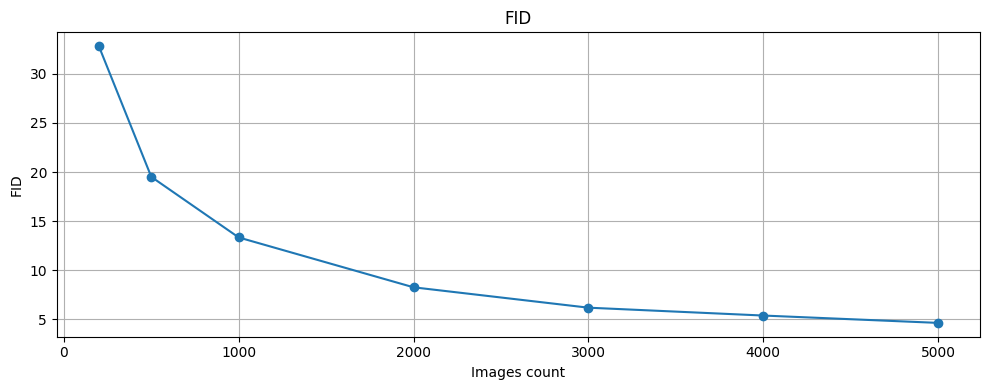

In [51]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))

ax.plot(images_count, fids, marker='o')
ax.grid(True)

ax.set_xlabel('Images count')
ax.set_ylabel('FID')
ax.set_title('FID')

fig.tight_layout()
plt.show()

Ваши выводы:

- Для всех точек графика используется одна обученная модель и один набор из 5000 генераций. При каждом $K$ сравниваются первые $K$ реальных и первые $K$ сгенерированных изображений, как разрешено в условии.
- При небольшом $K$ средние и ковариации признаков оцениваются менее устойчиво. Признаки имеют размерность 2048, поэтому, например, ковариация по 200 изображениям будет вырожденной. Это не мешает вычислить FID, но требует осторожной интерпретации.
- Снижение FID с ростом $K$ связано с изменением оценки распределений по выборке. Модель в этот момент не дообучается. Строгая монотонность при другом запуске не гарантируется.
- Для итоговой оценки использую $K=5000$ — наибольший объём из задания. Один запуск не показывает разброс метрики между разными наборами генераций.
- Использованы Inception V3 и преобразования изображений из шаблона. Сравнивать полученное число с другой работой можно только при одинаковых весах Inception, обработке изображений и размере выборки. Реальные изображения взяты из обучающей части MNIST, поэтому этот эксперимент сам по себе не доказывает отсутствие запоминания данных.

В следующей ячейке приведены таблица и численные итоги текущего запуска.

*Без выводов задание не будет засчитано.*


In [52]:
import pandas as pd

fid_table = pd.DataFrame({
    "Изображений в каждой выборке": images_count,
    "FID": fids
})
display(fid_table.round(3))
assert np.isfinite(fids).all()
assert np.isclose(fids[-1], fid_full)

first_fid, last_fid = float(fids[0]), float(fids[-1])
direction = "ниже" if last_fid < first_fid else "выше" if last_fid > first_fid else "такой же"
display(Markdown(
    f"При K = 200 FID равен **{first_fid:.3f}**, "
    f"а при K = 5000 — **{last_fid:.3f}**. "
    f"На полной выборке показатель {direction}, чем на самой маленькой. "
    "Это изменение оценки при разных объёмах данных, а не результат дообучения модели. "
    "Итоговый FID относится к 5000 изображениям и указанной в задании обработке признаков."
))


,Изображений в каждой выборке,FID
0,200,32.824
1,500,19.511
2,1000,13.342
3,2000,8.265
4,3000,6.190
5,4000,5.390
6,5000,4.641


При K = 200 FID равен **32.824**, а при K = 5000 — **4.641**. На полной выборке показатель ниже, чем на самой маленькой. Это изменение оценки при разных объёмах данных, а не результат дообучения модели. Итоговый FID относится к 5000 изображениям и указанной в задании обработке признаков.

### Итог эксперимента и файлы для сдачи

В таблице ниже собраны результаты текущего запуска. Для сдачи нужен этот ноутбук с сохранёнными выводами и отдельная ссылка на публичный проект W&B или Comet. В W&B доступ проекта должен быть Public; ссылку стоит проверить без входа в аккаунт. Чекпоинт лучше скачать отдельно, чтобы сохранить обученную модель после завершения сессии Colab.

In [53]:
summary = pd.DataFrame({
    "Показатель": [
        "Итераций обучения", "Последний MSE", "Средний MSE за последние 100 итераций",
        "Шагов обратного процесса", "Реальных изображений", "Сгенерированных изображений",
        "FID на 5000 изображениях"
    ],
    "Значение": [
        str(len(loss_history)), f"{last_train_mse:.5f}", f"{mean_last_100:.5f}",
        "1000", str(len(activations_real)), str(len(activations_fake)), f"{fid_full:.6f}"
    ]
})
display(summary)
assert Path("pretrained_ddpm_checkpoint.pth").is_file()
display(Markdown(f"**Эксперимент:** [{experiment_url}]({experiment_url})"))
if project_url:
    display(Markdown(f"**Проект для сдачи:** [{project_url}]({project_url})"))
print("Чекпоинт: pretrained_ddpm_checkpoint.pth")
print("Ноутбук для сдачи: ddpm_hw_bmmo-Shutov_Alexey.ipynb")

,Показатель,Значение
0,Итераций обучения,5000
1,Последний MSE,0.02343
2,Средний MSE за последние 100 итераций,0.01676
3,Шагов обратного процесса,1000
4,Реальных изображений,5000
5,Сгенерированных изображений,5000
6,FID на 5000 изображениях,4.641265


**Эксперимент:** [https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm/runs/rtu1kq01](https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm/runs/rtu1kq01)

**Проект для сдачи:** [https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm](https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm)

Чекпоинт: pretrained_ddpm_checkpoint.pth
Ноутбук для сдачи: ddpm_hw_bmmo-Shutov_Alexey.ipynb


### Обратная связь по заданию:

Задание помогло связать формулы из лекции с полным экспериментом: от добавления шума до генерации и оценки качества. Больше всего внимания потребовали индексы времени, последний шаг сэмплирования и матричный корень в FID. Отдельно стало понятно, почему при сравнении метрик нужно фиксировать размер выборки и обработку изображений.


### Использовали ли вы LLM? Если да, то как именно?

Да. Использовал ChatGPT для разбора формул DDPM, помощи с реализацией и подготовкой проверок. Полное обучение и генерацию запустил в Colab. Результаты проверены по сохранённым выводам, изображениям и FID.


### Использованные материалы

- [Лекция 5 курса: DDPM и FID](https://github.com/bmml-team/bmml_ftda/blob/e68351cda47e224e0fe3465f2780ca7ff37b330b/Lectures/lecture_5.pdf), страницы 2–8.
- [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239) — статья, указанная в условии.
- [Документация torchvision: Inception V3](https://docs.pytorch.org/vision/0.20/models/generated/torchvision.models.inception_v3.html) — загрузка предобученной модели.
- Исходный ноутбук задания: определения датасета, U-Net, EMA и каркас эксперимента.
- [Chong, Forsyth: Effectively Unbiased FID and Inception Score](https://arxiv.org/abs/1911.07023) — зависимость оценки FID от размера выборки.
